<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_071_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 71/365 — PCA
## How can we reduce many features into fewer dimensions without losing most of the information?

PCA — Principal Component Analysis — transforms correlated features into a smaller set of new variables called **principal components**.

- PC1 captures the most variance
- PC2 captures the next most
- and so on

The goal is to preserve as much useful variation as possible with fewer dimensions.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


## 1. Load a real 30-feature dataset


In [2]:
data=load_breast_cancer(as_frame=True)

X=data.data
y=data.target

print("Original shape:",X.shape)
print("Number of features:",X.shape[1])


Original shape: (569, 30)
Number of features: 30


## 2. Scale before PCA

PCA is sensitive to feature scale, so we standardize the data first.


In [3]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)


## 3. Reduce 30 features to 2 principal components


In [4]:
pca=PCA(n_components=2)

X_pca=pca.fit_transform(X_scaled)

print("Original dimensions:",X_scaled.shape[1])
print("Reduced dimensions:",X_pca.shape[1])
print("Explained variance ratio:",pca.explained_variance_ratio_)
print(
    "Total variance captured:",
    round(pca.explained_variance_ratio_.sum(),3)
)


Original dimensions: 30
Reduced dimensions: 2
Explained variance ratio: [0.44272026 0.18971182]
Total variance captured: 0.632


## 4. Visualize the compressed data


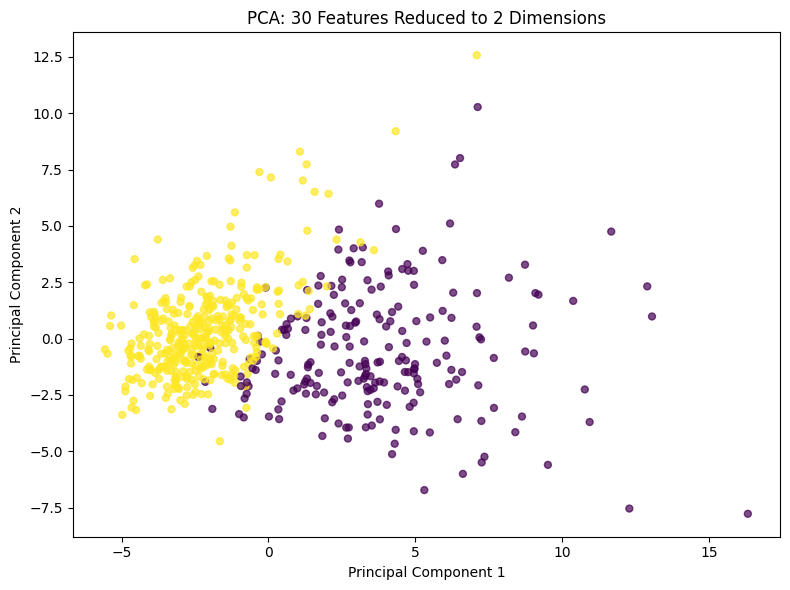

In [5]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    s=25,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: 30 Features Reduced to 2 Dimensions")
plt.tight_layout()
plt.show()


## 5. What is PCA doing?

PCA finds new directions through the data.

**PC1** points in the direction with the largest variance.

**PC2** captures the next-largest remaining variance and is orthogonal to PC1.

The process continues for later components.


## 6. Principal components are not original features

PC1 is not simply one original column.

Each principal component is a weighted combination of many original features.

This gives PCA compression power, but reduces interpretability.


## 7. How much variance do more components preserve?


In [6]:
pca_full=PCA()
pca_full.fit(X_scaled)

variance_df=pd.DataFrame({
    "Component":range(1,len(pca_full.explained_variance_ratio_)+1),
    "Explained Variance":pca_full.explained_variance_ratio_,
    "Cumulative Variance":pca_full.explained_variance_ratio_.cumsum()
})

display(variance_df.head(10).round(3))


,Component,Explained Variance,Cumulative Variance
0,1,0.443,0.443
1,2,0.190,0.632
2,3,0.094,0.726
3,4,0.066,0.792
4,5,0.055,0.847
5,6,0.040,0.888
6,7,0.023,0.910
7,8,0.016,0.926
8,9,0.014,0.940
9,10,0.012,0.952


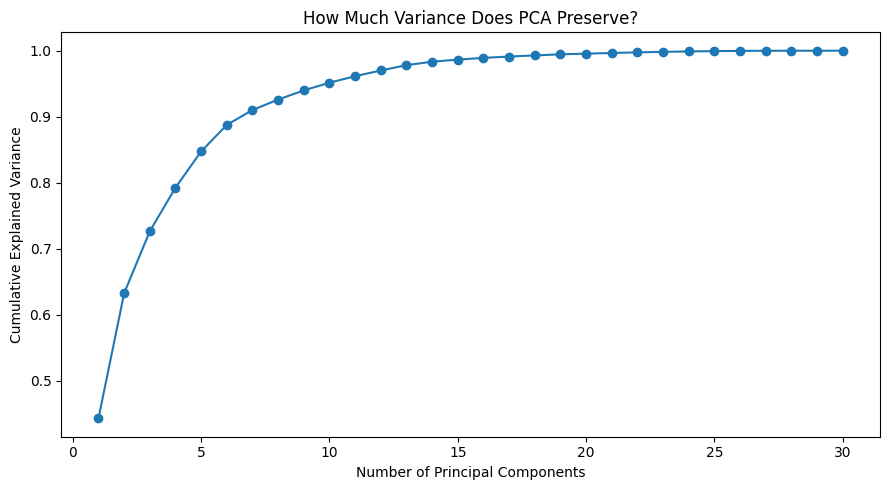

In [7]:
plt.figure(figsize=(9,5))

plt.plot(
    variance_df["Component"],
    variance_df["Cumulative Variance"],
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("How Much Variance Does PCA Preserve?")
plt.tight_layout()
plt.show()


## Enterprise intuition

PCA is useful when we have many correlated numerical features.

Examples:
- sensor measurements
- customer behavior features
- financial/risk variables
- image features
- embeddings

PCA can help with visualization, redundancy reduction, multicollinearity, and sometimes faster model training.


## Important limitations

- PCA is linear.
- Components are harder to interpret.
- High variance does not always mean high predictive importance.
- Scaling usually matters.
- Dimensionality reduction can discard useful information.


## What does this teach?

- PCA reduces dimensionality.
- It creates principal components from original features.
- PC1 captures the most variance.
- Later components capture remaining variance.
- PCA can compress correlated information.
- Scaling matters.
- Compression often comes at the cost of interpretability.

> **PCA asks: can I describe most of this dataset using fewer directions?**


## References

- https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- https://scikit-learn.org/stable/modules/decomposition.html#pca
- https://doi.org/10.1080/14786440109462720
